# EDA: `facilities` (Virtue Foundation dataset, DAIS 2026)

Table: `databricks_virtue_foundation_dataset_dais_2026.virtue_foundation_dataset.facilities`
Warehouse: `e3b50d583a2daca3` on `dbc-819afcb5-a64b` (CLI profile `dais2026`)

**Read-only.** The table is pulled once with a `SELECT *` and cached to `data/facilities_raw.pkl`.
All cleaning happens on a local copy; the source table is never written.

Goal: for every column, show **what values it can take**: full value counts for categoricals,
item counts for JSON-list columns, ranges plus unparseable values for numeric and date columns,
and patterns and examples for IDs and free text.

In [1]:
import json, re, subprocess, time, urllib.request
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 400)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# Chart style: one hue for single-series charts; orange only to flag misaligned rows.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Load (read-only query, cached locally)

In [2]:
PROFILE, WAREHOUSE = "dais2026", "e3b50d583a2daca3"
TABLE = "databricks_virtue_foundation_dataset_dais_2026.virtue_foundation_dataset.facilities"
CACHE = Path("data/facilities_raw.pkl")
REFRESH = False   # set True to re-pull from the warehouse

def _api(method, path, body=None):
    cmd = ["databricks", "-p", PROFILE, "api", method, path]
    if body is not None:
        cmd += ["--json", json.dumps(body)]
    return json.loads(subprocess.run(cmd, capture_output=True, text=True, check=True).stdout)

def run_sql(sql):
    """Run a query on the SQL warehouse via the Statement API; returns a DataFrame of strings.
    Uses EXTERNAL_LINKS because the full table exceeds the 25 MB inline limit."""
    r = _api("post", "/api/2.0/sql/statements", {
        "warehouse_id": WAREHOUSE, "statement": sql, "wait_timeout": "50s",
        "format": "JSON_ARRAY", "disposition": "EXTERNAL_LINKS"})
    while r["status"]["state"] in ("PENDING", "RUNNING"):
        time.sleep(3)
        r = _api("get", f"/api/2.0/sql/statements/{r['statement_id']}")
    if r["status"]["state"] != "SUCCEEDED":
        raise RuntimeError(r["status"])
    cols = [c["name"] for c in r["manifest"]["schema"]["columns"]]
    rows, links = [], r.get("result", {}).get("external_links", [])
    while links:
        nxt = None
        for link in links:
            # presigned cloud-storage URL: must NOT send the Databricks auth header
            with urllib.request.urlopen(link["external_link"]) as f:
                rows.extend(json.load(f))
            nxt = link.get("next_chunk_index")
        links = (_api("get", f"/api/2.0/sql/statements/{r['statement_id']}/result/chunks/{nxt}")
                 .get("external_links", []) if nxt is not None else [])
    df = pd.DataFrame(rows, columns=cols)
    assert len(df) == r["manifest"]["total_row_count"], "incomplete download"
    return df

if REFRESH or not CACHE.exists():
    CACHE.parent.mkdir(exist_ok=True)
    raw = run_sql(f"SELECT * FROM {TABLE}")
    raw.to_pickle(CACHE)
else:
    raw = pd.read_pickle(CACHE)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

TypeError: issubclass() arg 1 must be a class

## 2. Normalise missing values and flag misaligned rows

Almost every column is a `string`. Missing values usually appear as the literal text `'null'`,
or as `''`, `'[]'` or `'{}'`, not as SQL NULL. They are all mapped to `NaN` here.

**Broken rows.** Some text fields (e.g. `description`) contained line breaks, and the load split
them into extra rows. The result:
- **88 fragment rows**: the tail of a broken record, spread across the wrong columns. Their `unique_id`
  is not a UUID. They are **dropped** here (section 9 shows them).
- **30 truncated facilities**: real records (valid UUID) whose text was cut at the line break, so the
  columns after the break are empty. They are **kept** and flagged with `is_truncated`.

In [ ]:
MISSING_TOKENS = {"", "null", "none", "nan", "[]", "{}", '[""]'}

df = raw.copy()
for c in df.columns:
    s = df[c].astype("string")
    df[c] = s.mask(s.str.strip().str.lower().isin(MISSING_TOKENS))

is_fragment = ~df["unique_id"].str.fullmatch(r"[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}").fillna(False)
bad = df[is_fragment]
df = df[~is_fragment].reset_index(drop=True)
is_truncated = df["source"].ne("kie").fillna(True)   # complete records always end with source='kie'
N = len(df)

print(f"facilities kept: {N:,} (of which truncated: {is_truncated.sum()}) | fragment rows dropped: {len(bad)}")
print(f"duplicate unique_id among clean rows: {df.unique_id.duplicated().sum()}")

facilities kept: 10,000 (of which truncated: 30) | fragment rows dropped: 88
duplicate unique_id among clean rows: 11


## 3. Helpers

In [ ]:
def parse_list(v):
    """JSON-array string -> list of unique, non-empty, stripped items (order kept)."""
    if pd.isna(v):
        return None
    try:
        items = json.loads(v)
    except (ValueError, TypeError):
        return None
    if not isinstance(items, list):
        return None
    out = list(dict.fromkeys(str(x).strip() for x in items
                             if x is not None and str(x).strip().lower() not in MISSING_TOKENS))
    return out or None

def to_num(s):
    return pd.to_numeric(s, errors="coerce")

def value_table(s, n=None, denom=None, label="pct_of_non_missing"):
    """Value counts with a % column; n=None shows every value.
    denom defaults to the number of non-missing values; for exploded lists pass the row count."""
    vc = s.value_counts(dropna=True)
    t = pd.DataFrame({"count": vc, label: (100 * vc / (denom or vc.sum())).round(2)})
    return t if n is None else t.head(n)

def list_table(col, n=None):
    """Item counts for a list column, as % of rows that have a list."""
    L = lists[col].dropna()
    return value_table(L.explode(), n, denom=len(L), label="pct_of_rows_with_list")

def header(col, s):
    nm = s.isna().sum()
    display(Markdown(f"### `{col}`\nmissing **{nm:,}** ({100*nm/N:.1f}%) · distinct **{s.nunique():,}**"
                     + (" · *all values missing*" if nm == N else "")))

def barh(series, title, xlabel="rows", color=BLUE, figsize=(7, None)):
    series = series.iloc[::-1]
    h = figsize[1] or max(2.2, 0.28 * len(series) + 0.8)
    fig, ax = plt.subplots(figsize=(figsize[0], h))
    ax.barh([str(x) for x in series.index], series.values, color=color, height=0.7)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    for y, v in enumerate(series.values):
        ax.text(v, y, f" {v:,}", va="center", fontsize=8, color=INK2)
    plt.tight_layout(); plt.show()

## 4. Column overview

Each column is assigned a **kind**, which decides how its possible values are shown below.

In [ ]:
KIND = {
    # identifiers
    "unique_id": "id", "source_content_id": "id", "content_table_id": "id", "cluster_id": "id",
    "source_ids": "id_list",
    # low-cardinality categoricals
    "organization_type": "categorical", "facilityTypeId": "categorical", "operatorTypeId": "categorical",
    "address_country": "categorical", "address_countryCode": "categorical", "countries": "categorical",
    "acceptsVolunteers": "categorical", "affiliated_staff_presence": "categorical",
    "custom_logo_presence": "categorical", "source": "categorical",
    # lists of categorical codes
    "source_types": "cat_list", "affiliationTypeIds": "cat_list", "specialties": "cat_list",
    # lists of free-text items
    "procedure": "text_list", "equipment": "text_list", "capability": "text_list",
    "phone_numbers": "contact_list", "websites": "contact_list", "source_urls": "contact_list",
    # numbers stored as strings
    "yearEstablished": "numeric", "area": "numeric", "numberDoctors": "numeric", "capacity": "numeric",
    "distinct_social_media_presence_count": "numeric", "number_of_facts_about_the_organization": "numeric",
    "post_metrics_post_count": "numeric", "engagement_metrics_n_followers": "numeric",
    "engagement_metrics_n_likes": "numeric", "engagement_metrics_n_engagements": "numeric",
    "latitude": "numeric", "longitude": "numeric",
    # dates
    "recency_of_page_update": "date", "post_metrics_most_recent_social_media_post_date": "date",
    # location text
    "address_line1": "location", "address_line2": "location", "address_line3": "location",
    "address_city": "location", "address_stateOrRegion": "location", "address_zipOrPostcode": "location",
    "coordinates": "geojson",
    # contact & free text
    "name": "text", "description": "text", "email": "contact", "officialPhone": "contact",
    "officialWebsite": "contact", "facebookLink": "contact",
}
assert set(KIND) == set(df.columns), set(df.columns) ^ set(KIND)

overview = pd.DataFrame({
    "kind": pd.Series(KIND),
    "missing_pct": (100 * df.isna().mean()).round(1),
    "distinct": df.nunique(),
    "top_value": df.apply(lambda s: s.mode().iloc[0][:50] if s.notna().any() else None),
    "max_len": df.apply(lambda s: s.str.len().max()),
}).loc[df.columns]
overview

,kind,missing_pct,distinct,top_value,max_len
unique_id,id,0.0,9989,08344cdb-f455-4c22-8d31-a0a8e849124b,36
source_types,cat_list,0.3,6276,"[""overture"",""overture"",""overture"",""overture""]",698
source_ids,id_list,7.3,9231,"[""08f3d914d564b56903cb9f319f87649a"",""08f6861128194",1751
source_content_id,id,0.0,9067,cddadadb-259a-49d3-8240-e3bb9bbdc209,36
name,text,0.0,9507,Apollo Clinic,188
organization_type,categorical,0.0,1,facility,8
content_table_id,id,0.0,9067,cddadadb-259a-49d3-8240-e3bb9bbdc209,36
phone_numbers,contact_list,2.8,9700,"[""+919693969347"",""+918001031041""]",838
officialPhone,contact,5.0,9155,+919693969347,16
email,contact,14.6,8044,[email protected],90


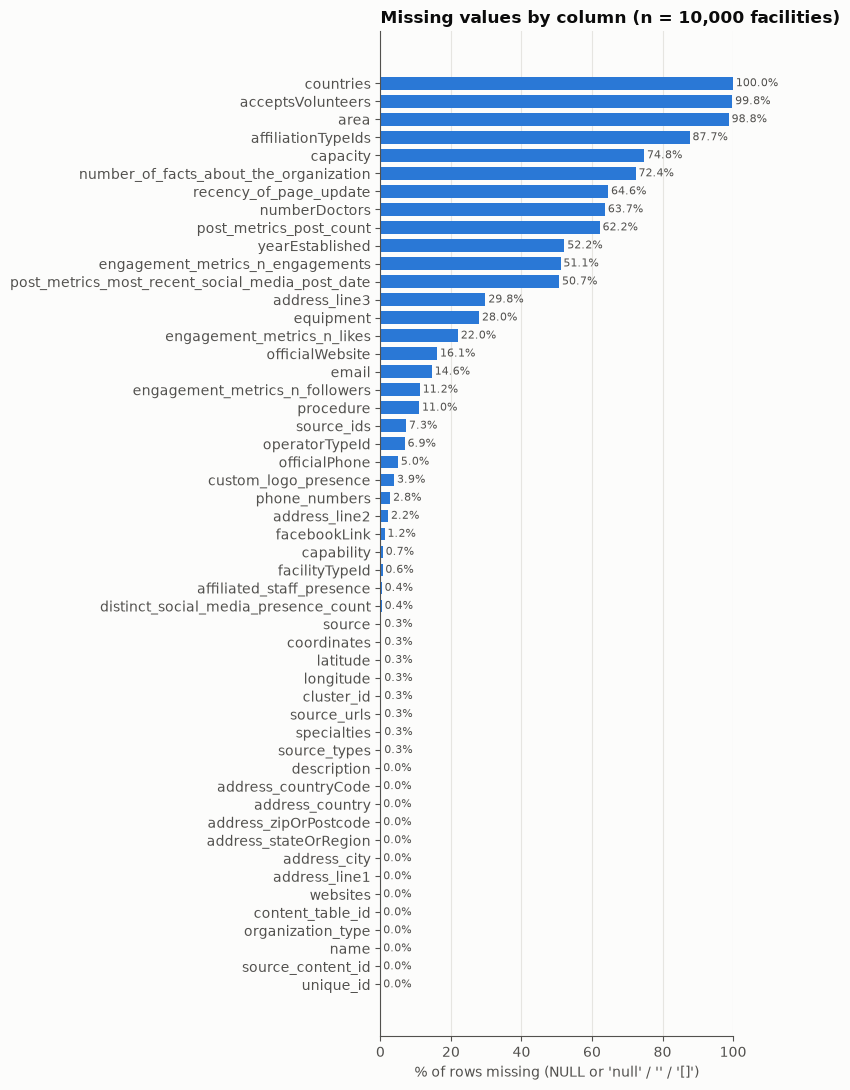

In [ ]:
miss = overview.missing_pct.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(miss.index[::-1], miss.values[::-1], color=BLUE, height=0.7)
ax.set_xlim(0, 100); ax.set_xlabel("% of rows missing (NULL or 'null' / '' / '[]')")
ax.set_title(f"Missing values by column (n = {N:,} facilities)"); ax.grid(axis="y", visible=False)
for y, v in enumerate(miss.values[::-1]):
    ax.text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
plt.tight_layout(); plt.show()

## 5. Categorical columns: every possible value

In [ ]:
for col in [c for c, k in KIND.items() if k == "categorical"]:
    header(col, df[col])
    if df[col].notna().any():
        display(value_table(df[col]))

### `organization_type`
missing **0** (0.0%) · distinct **1**

,count,pct_of_non_missing
organization_type,,
facility,10000,100.0


### `facilityTypeId`
missing **57** (0.6%) · distinct **7**

,count,pct_of_non_missing
facilityTypeId,,
hospital,5637,56.69
clinic,3782,38.04
dentist,490,4.93
doctor,21,0.21
farmacy,10,0.1
pharmacy,2,0.02
nursing_home,1,0.01


### `operatorTypeId`
missing **687** (6.9%) · distinct **3**

,count,pct_of_non_missing
operatorTypeId,,
private,8842,94.94
public,469,5.04
government,2,0.02


... (9 outputs left out)

### `custom_logo_presence`
missing **391** (3.9%) · distinct **2**

,count,pct_of_non_missing
custom_logo_presence,,
true,8611,89.61
false,998,10.39


### `source`
missing **30** (0.3%) · distinct **1**

,count,pct_of_non_missing
source,,
kie,9970,100.0


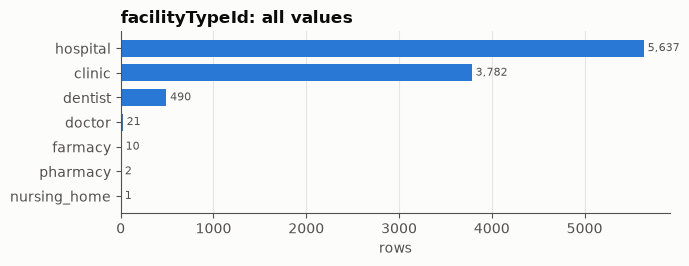

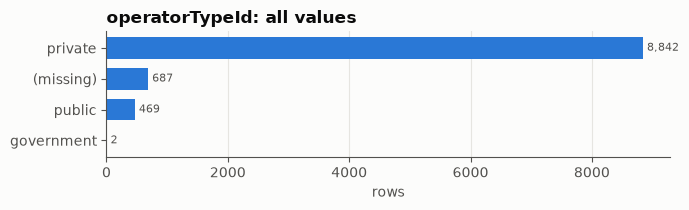

In [ ]:
barh(df.facilityTypeId.value_counts(), "facilityTypeId: all values")
barh(df.operatorTypeId.fillna("(missing)").value_counts(), "operatorTypeId: all values")

In [ ]:
display(Markdown("**facilityTypeId × operatorTypeId**"))
pd.crosstab(df.facilityTypeId.fillna("(missing)"), df.operatorTypeId.fillna("(missing)"),
            margins=True).sort_values("All", ascending=False)

**facilityTypeId × operatorTypeId**

operatorTypeId,(missing),government,private,public,All
facilityTypeId,,,,,
All,687,2,8842,469,10000
hospital,519,2,4674,442,5637
clinic,129,0,3627,26,3782
dentist,6,0,484,0,490
(missing),31,0,26,0,57
doctor,1,0,20,0,21
farmacy,1,0,8,1,10
pharmacy,0,0,2,0,2
nursing_home,0,0,1,0,1


## 6. List columns (JSON arrays)

Lists are parsed, duplicates within a row are removed (rows often repeat the same item),
and the items are then counted across rows. The counts are **rows containing the item**.

In [ ]:
lists = {c: df[c].map(parse_list) for c, k in KIND.items() if k.endswith("_list")}

def list_summary(col):
    L = lists[col]
    n_items = L.dropna().map(len)
    items = L.dropna().explode()
    return {"rows_with_list": L.notna().sum(), "distinct_items": items.nunique(),
            "items_per_row_median": n_items.median(), "items_per_row_max": n_items.max()}

pd.DataFrame({c: list_summary(c) for c in lists}).T

,rows_with_list,distinct_items,items_per_row_median,items_per_row_max
source_ids,9269.0,29356.0,3.0,35.0
source_types,9972.0,5.0,2.0,5.0
affiliationTypeIds,1229.0,19.0,1.0,6.0
specialties,9970.0,2927.0,10.0,50.0
procedure,8847.0,89188.0,12.0,50.0
equipment,7116.0,35142.0,4.0,50.0
capability,9929.0,168148.0,18.0,50.0
phone_numbers,9719.0,37161.0,3.0,48.0
websites,10000.0,120917.0,10.0,50.0
source_urls,9970.0,109501.0,8.0,50.0


### 6a. Lists of codes: every possible value

In [ ]:
for col in ["source_types", "affiliationTypeIds"]:
    header(col, df[col])
    display(list_table(col))

### `source_types`
missing **28** (0.3%) · distinct **6,276**

,count,pct_of_rows_with_list
source_types,,
overture,9165,91.91
dynamic,6942,69.61
constant,3393,34.03
mongo_facility,1124,11.27
mongo_ngo,228,2.29


### `affiliationTypeIds`
missing **8,771** (87.7%) · distinct **296**

,count,pct_of_rows_with_list
affiliationTypeIds,,
government,672,54.68
academic,471,38.32
philanthropy-legacy,207,16.84
faith-tradition,123,10.01
community,112,9.11
private,19,1.55
public,4,0.33
corporate,1,0.08
NMC,1,0.08


### `specialties`
There are about 2,900 distinct codes, but they form a long tail: roughly 300 appear in 10 or more rows, and about 2,000 appear only once
(variants such as `holisticDentistry`). The table below lists every code found in at least 10 rows. The complete list is in the CSV export (section 10).

In [ ]:
header("specialties", df.specialties)
spec_t = list_table("specialties")
print(f"codes in >=10 rows: {(spec_t['count'] >= 10).sum()} | in exactly 1 row: {(spec_t['count'] == 1).sum()}")
with pd.option_context("display.max_rows", 500):
    display(spec_t[spec_t["count"] >= 10])

### `specialties`
missing **30** (0.3%) · distinct **9,660**

codes in >=10 rows: 301 | in exactly 1 row: 1971


,count,pct_of_rows_with_list
specialties,,
internalMedicine,6847,68.68
familyMedicine,5178,51.94
gynecologyAndObstetrics,4497,45.11
dentistry,4192,42.05
orthopedicSurgery,3526,35.37
pediatrics,3438,34.48
generalSurgery,3198,32.08
cardiology,3011,30.20
radiology,2999,30.08


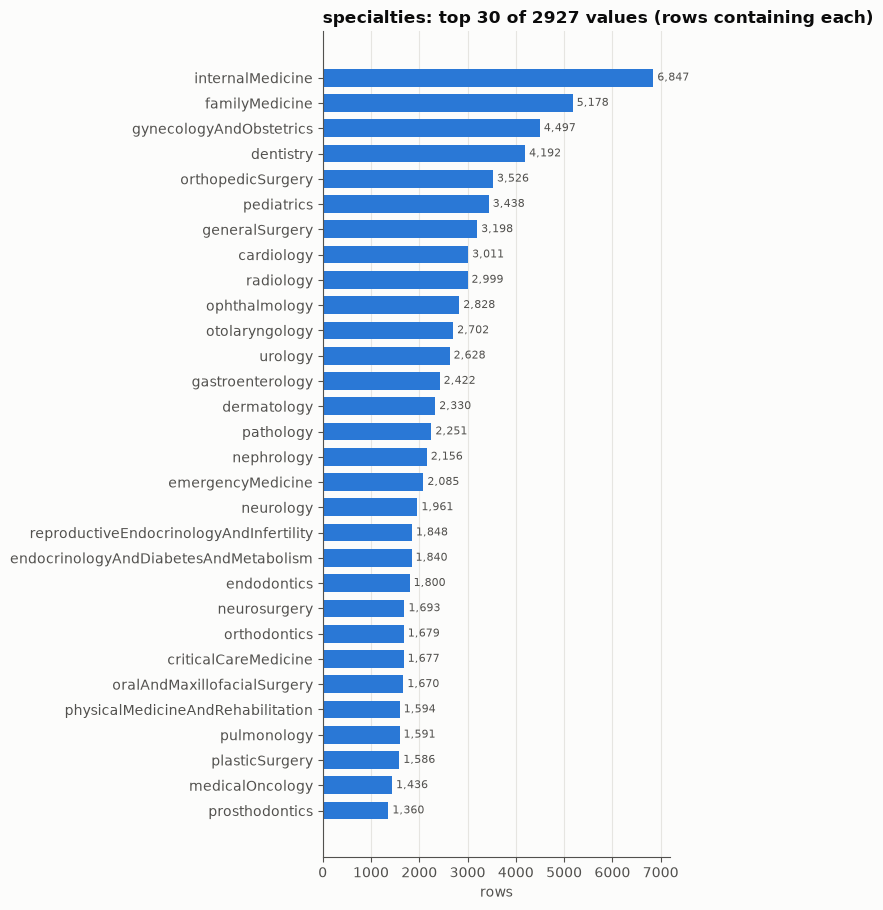

In [ ]:
spec = lists["specialties"].dropna().explode().value_counts()
barh(spec.head(30), f"specialties: top 30 of {len(spec)} values (rows containing each)")

### 6b. Lists of free text: `procedure`, `equipment`, `capability`

These hold free-text sentences, so the number of distinct values is in the thousands. The output shows
the most common items and the number of items per row.

### `procedure`
missing **1,102** (11.0%) · distinct **8,811**

distinct items: 89,188 | items appearing in only 1 row: 76,159


,count,pct_of_rows_with_list
procedure,,
Dental implants,338,3.82
Dental Implants,293,3.31
Root canal treatment,281,3.18
Laparoscopic surgery,258,2.92
Root Canal Treatment,237,2.68
Arthroscopy,233,2.63
Teeth whitening,222,2.51
Teeth Whitening,217,2.45
Dentures,217,2.45


### `equipment`
missing **2,795** (27.9%) · distinct **6,887**

distinct items: 35,142 | items appearing in only 1 row: 31,708


,count,pct_of_rows_with_list
equipment,,
CT scanner,515,7.24
Wheelchair accessible entrance and exit,360,5.06
MRI scanner,318,4.47
Wheelchair-accessible entrance and exit,310,4.36
X-ray imaging equipment,274,3.85
Ultrasound machine,211,2.97
ECG machine,205,2.88
Wheelchair-accessible car parking,180,2.53
X-ray machine,177,2.49


### `capability`
missing **70** (0.7%) · distinct **9,916**

distinct items: 168,148 | items appearing in only 1 row: 156,428


,count,pct_of_rows_with_list
capability,,
Outpatient dental clinic,531,5.35
Operates 24/7,493,4.97
24/7 emergency care,477,4.80
Provides 24/7 emergency care,470,4.73
Private hospital,437,4.40
Inpatient and outpatient services,435,4.38
NABH accredited,423,4.26
Open 24/7,377,3.80
Open 24 Hrs,344,3.46


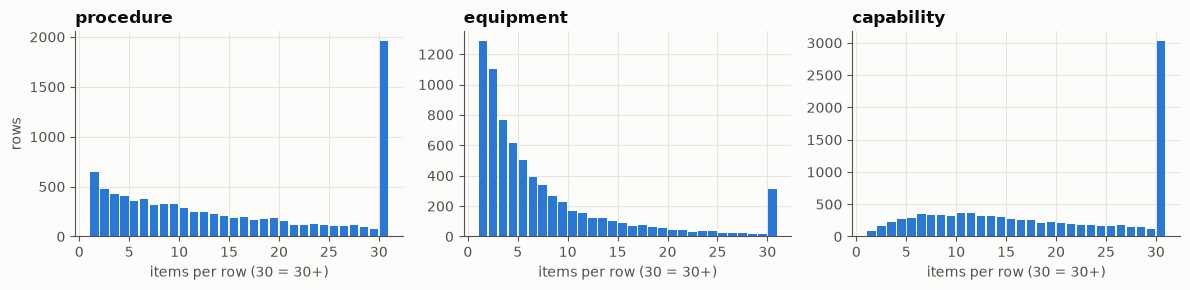

In [ ]:
for col in ["procedure", "equipment", "capability"]:
    header(col, df[col])
    items = lists[col].dropna().explode()
    print(f"distinct items: {items.nunique():,} | items appearing in only 1 row: "
          f"{(items.value_counts() == 1).sum():,}")
    display(list_table(col, 25))

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
for ax, col in zip(axes, ["procedure", "equipment", "capability"]):
    k = lists[col].dropna().map(len).clip(upper=30)
    ax.hist(k, bins=range(1, 32), color=BLUE, rwidth=0.85)
    ax.set_title(col); ax.set_xlabel("items per row (30 = 30+)")
axes[0].set_ylabel("rows")
plt.tight_layout(); plt.show()

### 6c. Contact and URL lists: `phone_numbers`, `websites`, `source_urls` (shown as domains)

In [ ]:
def domain(u):
    u = u.strip().lower()
    host = urlparse(u if "://" in u else "http://" + u).netloc
    return host.removeprefix("www.") or None

for col in ["websites", "source_urls"]:
    header(col, df[col])
    L = lists[col].dropna().map(lambda l: list({domain(u) for u in l} - {None}))
    print(f"distinct domains: {L.explode().nunique():,}")
    display(value_table(L.explode(), 20, denom=len(L), label="pct_of_rows_with_list"))

header("phone_numbers", df.phone_numbers)
ph = lists["phone_numbers"].dropna().explode()
print("prefix pattern of individual numbers:")
display(value_table(ph.str.replace(r"\d", "9", regex=True).str[:6] + " (len " + ph.str.len().astype(str) + ")", 10))

### `websites`
missing **0** (0.0%) · distinct **9,989**

distinct domains: 16,477


,count,pct_of_rows_with_list
websites,,
facebook.com,8824,88.24
justdial.com,5431,54.31
practo.com,2703,27.03
mappls.com,1660,16.60
medindia.net,1539,15.39
onefivenine.com,1466,14.66
proptiger.com,1126,11.26
in.linkedin.com,1077,10.77
policyx.com,1024,10.24


### `source_urls`
missing **30** (0.3%) · distinct **9,959**

distinct domains: 12,144


,count,pct_of_rows_with_list
source_urls,,
facebook.com,8849,88.76
justdial.com,5432,54.48
practo.com,2707,27.15
mappls.com,1679,16.84
medindia.net,1548,15.53
onefivenine.com,1469,14.73
proptiger.com,1142,11.45
in.linkedin.com,1096,10.99
policyx.com,1033,10.36


### `phone_numbers`
missing **281** (2.8%) · distinct **9,700**

prefix pattern of individual numbers:


,count,pct_of_non_missing
phone_numbers,,
+99999 (len 13),38801,97.66
999999 (len 11),496,1.25
+99999 (len 14),353,0.89
+99999 (len 12),43,0.11
+99999 (len 11),18,0.05
+99999 (len 15),13,0.03
+99999 (len 16),5,0.01
+99999 (len 10),2,0.01
999999 (len 13),1,0.00


## 7. Numeric columns (stored as strings)

`unparseable` counts non-missing values that are not numbers. The table also lists the distinct
values when there are few of them.

In [ ]:
num_cols = [c for c, k in KIND.items() if k == "numeric"]
num = df[num_cols].apply(to_num)

rows = {}
for c in num_cols:
    s = num[c].dropna()
    rows[c] = {"non_missing": df[c].notna().sum(),
               "unparseable": int(df[c].notna().sum() - len(s)),
               "min": s.min(), "p25": s.quantile(.25), "median": s.median(),
               "p75": s.quantile(.75), "p99": s.quantile(.99), "max": s.max(),
               "distinct": s.nunique()}
pd.DataFrame(rows).T.round(2)

,non_missing,unparseable,min,p25,median,p75,p99,max,distinct
yearEstablished,4782.0,0.0,0.00,1993.00,2005.00,2014.00,2023.00,2025.00,146.0
area,125.0,0.0,0.00,150.00,5550.00,32500.00,1049249.28,1125000.00,93.0
numberDoctors,3630.0,0.0,0.00,1.00,2.00,10.00,408.52,15000.00,167.0
capacity,2516.0,0.0,0.00,35.00,100.00,200.00,1668.25,200000.00,311.0
distinct_social_media_presence_count,9965.0,0.0,0.00,2.00,4.00,5.00,9.00,11.00,12.0
number_of_facts_about_the_organization,2757.0,0.0,0.00,3.00,5.00,7.00,31.44,442.00,52.0
post_metrics_post_count,3784.0,0.0,0.00,0.00,0.00,1.00,270.97,59000.00,99.0
engagement_metrics_n_followers,8884.0,0.0,0.00,11.00,244.50,1000.00,35323.68,15000000.00,1320.0
engagement_metrics_n_likes,7800.0,0.0,0.00,2.00,69.00,745.00,18000.00,384000.00,1030.0
engagement_metrics_n_engagements,4887.0,0.0,0.00,0.00,0.00,13.00,2776.54,121855.00,434.0


In [ ]:
for c in num_cols:
    bad_vals = df[c][df[c].notna() & num[c].isna()]
    if len(bad_vals):
        print(f"{c}: unparseable values ->", bad_vals.str[:60].value_counts().head(5).to_dict())

for c in ["distinct_social_media_presence_count", "number_of_facts_about_the_organization"]:
    header(c, df[c])
    display(value_table(num[c].astype("Int64")).sort_index().T)

### `distinct_social_media_presence_count`
missing **35** (0.3%) · distinct **12**

distinct_social_media_presence_count,0,1,2,3,4,5,6,7,8,9,10,11
count,434,1917,892,1677,1284,2737,715,107,50,149,1,2
pct_of_non_missing,4.36,19.24,8.95,16.83,12.89,27.47,7.18,1.07,0.5,1.5,0.01,0.02


### `number_of_facts_about_the_organization`
missing **7,243** (72.4%) · distinct **52**

number_of_facts_about_the_organization,0,1,2,3,4,5,6,7,8,9,...,103,105,116,139,142,144,195,208,294,442
count,21,156,186,419,523,415,317,159,129,102,...,1,1,1,1,1,1,1,1,1,1
pct_of_non_missing,0.76,5.66,6.75,15.2,18.97,15.05,11.5,5.77,4.68,3.7,...,0.04,0.04,0.04,0.04,0.04,0.04,0.04,0.04,0.04,0.04


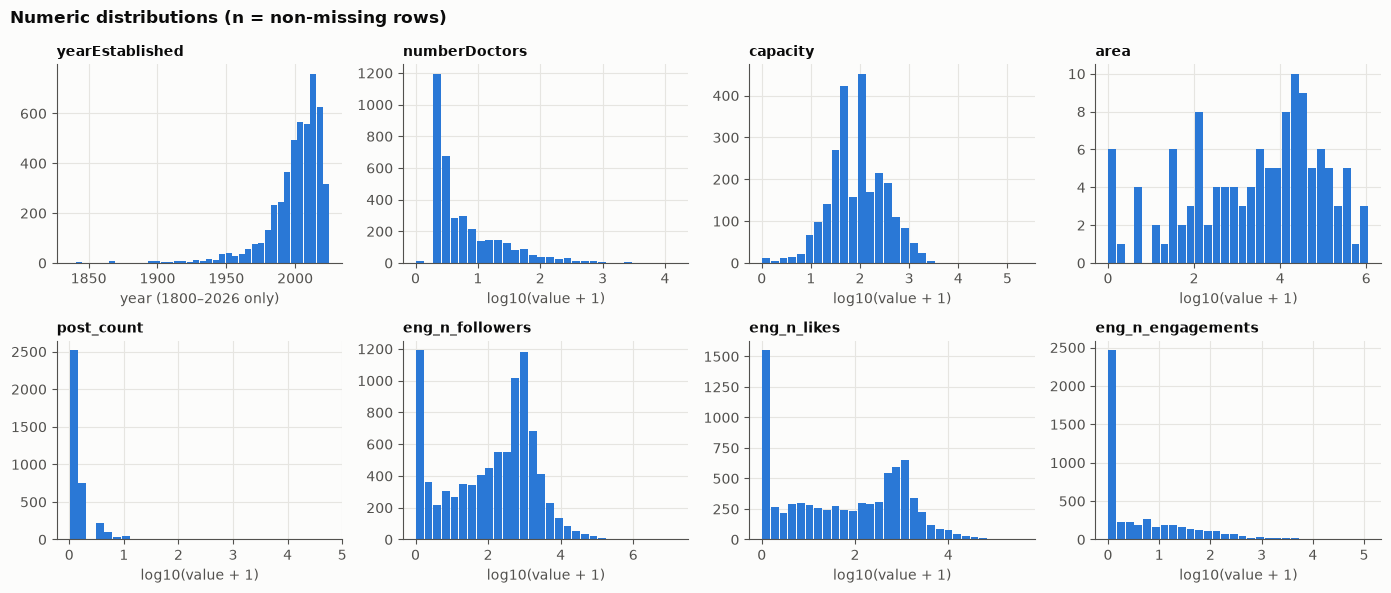

yearEstablished outside 1800–2026: 7 -> [np.int64(0), np.int64(7), np.int64(15), np.int64(1723), np.int64(1756)]


In [ ]:
plot_cols = ["yearEstablished", "numberDoctors", "capacity", "area", "post_metrics_post_count",
             "engagement_metrics_n_followers", "engagement_metrics_n_likes", "engagement_metrics_n_engagements"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.flat, plot_cols):
    s = num[c].dropna()
    if c == "yearEstablished":
        s = s[(s >= 1800) & (s <= 2026)]
        ax.hist(s, bins=40, color=BLUE, rwidth=0.9); ax.set_xlabel("year (1800–2026 only)")
    else:
        ax.hist(np.log10(s + 1), bins=30, color=BLUE, rwidth=0.9); ax.set_xlabel("log10(value + 1)")
    ax.set_title(c.replace("engagement_metrics_", "eng_").replace("post_metrics_", ""), fontsize=10)
fig.suptitle(f"Numeric distributions (n = non-missing rows)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

ye = num.yearEstablished.dropna()
print(f"yearEstablished outside 1800–2026: {((ye < 1800) | (ye > 2026)).sum()} ->",
      sorted(ye[(ye < 1800) | (ye > 2026)].unique())[:15])

## 8. Dates, location, contact and ID columns

In [ ]:
for c in [c for c, k in KIND.items() if k == "date"]:
    header(c, df[c])
    d = pd.to_datetime(df[c], errors="coerce", format="%Y-%m-%d")
    print(f"range: {d.min().date()} → {d.max().date()} | unparseable: {df[c].notna().sum() - d.notna().sum()}")
    display(d.dt.year.value_counts().sort_index().rename("rows").to_frame().T)

### `recency_of_page_update`
missing **6,457** (64.6%) · distinct **870**

range: 2003-09-04 → 2027-07-20 | unparseable: 11


recency_of_page_update,2003.0,2006.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,...,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0,2027.0
rows,2,2,3,2,1,11,11,40,18,21,...,21,53,95,82,80,264,555,2241,4,1


### `post_metrics_most_recent_social_media_post_date`
missing **5,068** (50.7%) · distinct **2,114**

range: 2009-06-29 → 2026-01-22 | unparseable: 18


post_metrics_most_recent_social_media_post_date,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0,2026.0
rows,6,2,5,8,12,40,35,67,88,177,229,349,385,562,833,1514,560,42


### Location: every state/region value, top cities and postcodes

In [ ]:
header("address_stateOrRegion", df.address_stateOrRegion)
display(value_table(df.address_stateOrRegion))

### `address_stateOrRegion`
missing **0** (0.0%) · distinct **234**

,count,pct_of_non_missing
address_stateOrRegion,,
Maharashtra,1575,15.75
Gujarat,981,9.81
Uttar Pradesh,919,9.19
Tamil Nadu,780,7.8
Karnataka,529,5.29
Kerala,483,4.83
West Bengal,477,4.77
Punjab,469,4.69
Haryana,462,4.62


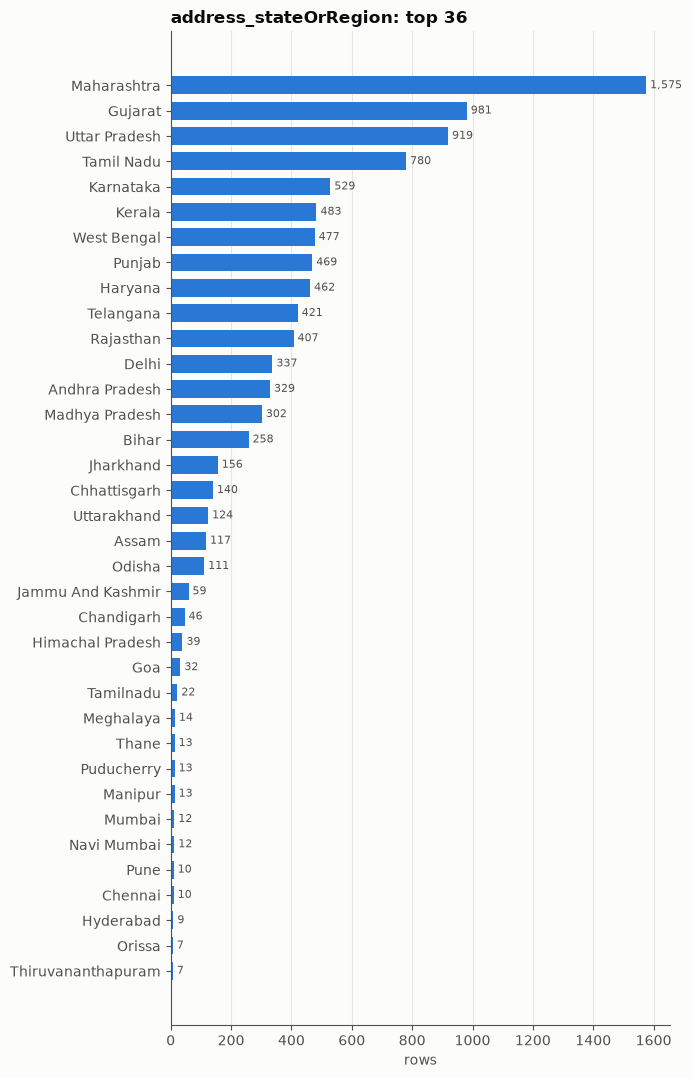

### `address_city`
missing **0** (0.0%) · distinct **1,628**

,count,pct_of_non_missing
address_city,,
Mumbai,365,3.65
Hyderabad,358,3.58
Ahmedabad,326,3.26
Chennai,326,3.26
Pune,274,2.74
Kolkata,243,2.43
Bangalore,204,2.04
Jaipur,190,1.9
Surat,164,1.64


### `address_zipOrPostcode`
missing **4** (0.0%) · distinct **3,194**

,count,pct_of_non_missing
address_zipOrPostcode,,
143001,65,0.65
248001,55,0.55
122001,49,0.49
380015,45,0.45
492001,43,0.43
144001,43,0.43
201301,37,0.37
452001,37,0.37
800020,33,0.33


### `address_line1`
missing **0** (0.0%) · distinct **9,657**

,count,pct_of_non_missing
address_line1,,
Main Road,22,0.22
Hospital Road,13,0.13
Vip Road,11,0.11
Civil Lines,9,0.09
Hospital Rd,8,0.08
1st Floor,8,0.08
Medical College Road,7,0.07
Mg Road,7,0.07
Station Road,7,0.07


### `address_line2`
missing **215** (2.1%) · distinct **8,885**

,count,pct_of_non_missing
address_line2,,
Civil Lines,27,0.28
Model Town,23,0.24
Shastri Nagar,17,0.17
Ashok Nagar,16,0.16
Kankarbagh,13,0.13
Indira Nagar,11,0.11
Station Road,11,0.11
Shivaji Nagar,10,0.1
Krishna Nagar,10,0.1


### `address_line3`
missing **2,978** (29.8%) · distinct **6,044**

,count,pct_of_non_missing
address_line3,,
Civil Lines,30,0.43
Model Town,13,0.19
Gandhi Nagar,11,0.16
Station Road,11,0.16
Shastri Nagar,10,0.14
Malviya Nagar,10,0.14
Thane West,9,0.13
Gomti Nagar,8,0.11
Satellite,8,0.11


postcodes that are valid 6-digit Indian PINs: 9,766 / 9,996


In [ ]:
barh(df.address_stateOrRegion.value_counts().head(36), "address_stateOrRegion: top 36")
for c in ["address_city", "address_zipOrPostcode", "address_line1", "address_line2", "address_line3"]:
    header(c, df[c])
    display(value_table(df[c], 15))
zip_ok = df.address_zipOrPostcode.str.fullmatch(r"[1-9]\d{5}")
print(f"postcodes that are valid 6-digit Indian PINs: {zip_ok.sum():,} / {df.address_zipOrPostcode.notna().sum():,}")

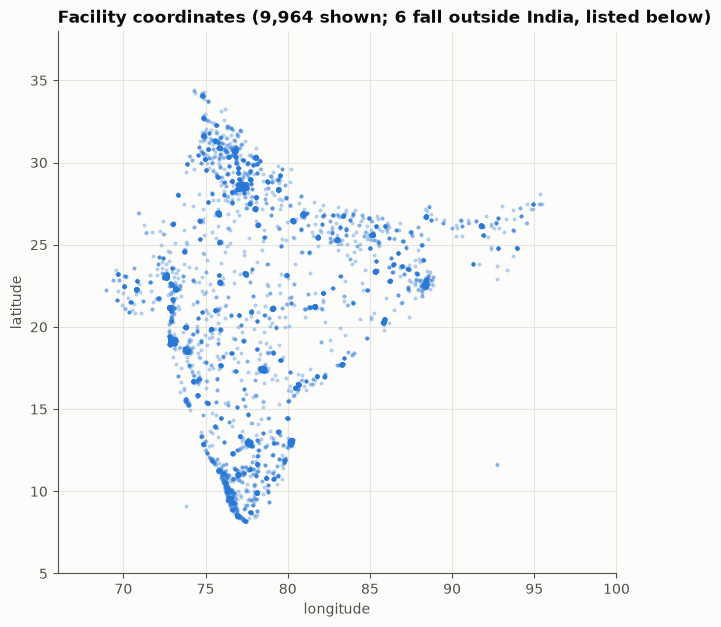

coordinates GeoJSON types: {'Point': 9970}


,name,address_city,address_stateOrRegion,latitude,longitude
1617,Cura Imaging & Gastro Clinic,Nagpur,Maharashtra,2.9529342651367188,41.38715744018555
3848,Hzb Arogyam Multispeciality Hospital,Hazaribagh,Jharkhand,46.07322692871094,106.171875
7195,The Family Tree Hospital,Tirupati,Andhra Pradesh,32.96258544921875,7.479839324951172
8274,Sanjivani Multi Speciality Hospital,Chengannur,Alappuzha,59.949684143066406,-38.26263427734375
8921,Krishna Hospital Multispeciality,Lucknow,Uttar Pradesh,-81.706298828125,26.953109741210938
9728,Cardia Health Care,Noida,Uttar Pradesh,7.710991382598877,109.6875


In [ ]:
lat, lon = num.latitude, num.longitude
in_india = lat.between(6, 37) & lon.between(68, 98)
fig, ax = plt.subplots(figsize=(6.5, 7))
n_out = int((~in_india & lat.notna()).sum())
ax.scatter(lon[in_india], lat[in_india], s=8, color=BLUE, alpha=0.35, linewidths=0)
ax.set_xlim(66, 100); ax.set_ylim(5, 38); ax.set_aspect("equal")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title(f"Facility coordinates ({in_india.sum():,} shown; {n_out} fall outside India, listed below)")
plt.tight_layout(); plt.show()

print("coordinates GeoJSON types:", df.coordinates.dropna().map(lambda v: json.loads(v)["type"]).value_counts().to_dict())
display(df.loc[~in_india & lat.notna(), ["name", "address_city", "address_stateOrRegion", "latitude", "longitude"]])

### Contact fields

In [ ]:
for c in ["email", "officialPhone", "officialWebsite", "facebookLink"]:
    header(c, df[c])
    display(value_table(df[c], 8))

e = df.email.dropna()
print("email patterns:")
print(pd.Series({
    "valid single address": e.str.fullmatch(r"[^@\s\[\]\"]+@[^@\s]+\.[a-z]{2,}", case=False).sum(),
    "JSON list of addresses": e.str.startswith("[").sum(),
    "Cloudflare-obfuscated '[email protected]'": e.str.contains("protected", regex=False).sum(),
}).to_string())
p = df.officialPhone.dropna()
print("\nofficialPhone '+91' + 10 digits:", p.str.fullmatch(r"\+91\d{10}").sum(), "/", len(p))
print("officialWebsite == 'true' (boolean leaked into URL field):", (df.officialWebsite == "true").sum())
print("facebookLink not starting with http:", (~df.facebookLink.dropna().str.startswith("http")).sum(),
      "->", df.facebookLink.dropna()[~df.facebookLink.dropna().str.startswith("http")].value_counts().head(5).to_dict())

### `email`
missing **1,455** (14.6%) · distinct **8,044**

,count,pct_of_non_missing
email,,
[email protected],349,4.08
care@redcliffelabs.com,10,0.12
help@indiraivf.in,9,0.11
[email protected],6,0.07
"[""[email protected]"",""[email protected]""]",6,0.07
info@apollohospitals.com,5,0.06
online@parthadental.com,5,0.06
assistance@kimshospitals.com,4,0.05


### `officialPhone`
missing **497** (5.0%) · distinct **9,155**

,count,pct_of_non_missing
officialPhone,,
+919693969347,87,0.92
+914061626364,34,0.36
+918448879134,25,0.26
+918860688606,16,0.17
+917303555015,14,0.15
+911143364336,10,0.11
+919791173039,8,0.08
+918001031041,8,0.08


### `officialWebsite`
missing **1,607** (16.1%) · distinct **8,000**

,count,pct_of_non_missing
officialWebsite,,
business.site,33,0.39
esic.nic.in,12,0.14
manipalhospitals.com,11,0.13
asgeyehospital.com,11,0.13
fortishealthcare.com,10,0.12
redcliffelabs.com,10,0.12
maxlab.co.in,10,0.12
apollohospitals.com,9,0.11


### `facebookLink`
missing **118** (1.2%) · distinct **9,871**

,count,pct_of_non_missing
facebookLink,,
https://www.facebook.com/390181364393285,2,0.02
https://www.facebook.com/154355864424582,2,0.02
https://www.facebook.com/235940656847441,2,0.02
https://www.facebook.com/2128037103933010,2,0.02
https://www.facebook.com/1888123388109153,2,0.02
https://www.facebook.com/191940224717665,2,0.02
https://www.facebook.com/1886178838343365,2,0.02
https://www.facebook.com/214238895268977,2,0.02


email patterns:
valid single address                         8114
JSON list of addresses                        392
Cloudflare-obfuscated '[email protected]'     363

officialPhone '+91' + 10 digits: 9448 / 9503
officialWebsite == 'true' (boolean leaked into URL field): 0
facebookLink not starting with http: 6 -> {'facebook.com/shraddhahospitals': 1, 'facebook.com/shikharhospital': 1, 'www.facebook.com/nuhospitals': 1, 'facebook.com/sadamangalamkolhapur': 1, 'facebook.com/alkaridevihospitaldhanbad': 1}


### Free text and IDs

In [ ]:
for c in ["name", "description"]:
    header(c, df[c])
    L = df[c].str.len()
    print(f"length: median {L.median():.0f}, p95 {L.quantile(.95):.0f}, max {L.max():.0f}")
    display(value_table(df[c], 12))

display(Markdown("**Identifier columns**: are they unique?"))
id_cols = [c for c, k in KIND.items() if k == "id"]
pd.DataFrame({c: {"non_missing": df[c].notna().sum(), "distinct": df[c].nunique(),
                  "duplicated_rows": df[c].dropna().duplicated(keep=False).sum(),
                  "looks_like": "uuid" if df[c].dropna().str.fullmatch(r"[0-9a-f-]{36}").mean() > .9 else "hex/other"}
              for c in id_cols}).T

### `name`
missing **0** (0.0%) · distinct **9,507**

length: median 24, p95 55, max 188


,count,pct_of_non_missing
name,,
Apollo Clinic,10,0.1
City Hospital,8,0.08
Life Care Hospital,6,0.06
Bansal Hospital,5,0.05
Fortis Hospital,5,0.05
Ankur Hospital,5,0.05
Surya Hospital,5,0.05
Pathkind Labs,5,0.05
Balaji Hospital,5,0.05


### `description`
missing **0** (0.0%) · distinct **9,571**

length: median 115, p95 535, max 6557


,count,pct_of_non_missing
description,,
Hospital,40,0.4
Open 24 Hrs,34,0.34
Dental Clinic,30,0.3
Providing exceptional cardiac care to the community,22,0.22
Diagnostic Center,14,0.14
Clinic,12,0.12
Dentist & Dental Office,9,0.09
Pathology & Diagnostic Lab,9,0.09
Pediatric Clinic,8,0.08


**Identifier columns**: are they unique?

,non_missing,distinct,duplicated_rows,looks_like
unique_id,10000,9989,22,uuid
source_content_id,10000,9067,1346,uuid
content_table_id,10000,9067,1346,uuid
cluster_id,9970,9959,22,hex/other


In [ ]:
dups = df[df.unique_id.duplicated(keep=False)].sort_values("unique_id")
print(f"{dups.unique_id.nunique()} unique_ids appear more than once; "
      f"rows identical apart from the id? {dups.drop(columns='unique_id').duplicated(keep=False).all()}")
dups[["unique_id", "name", "address_city", "facilityTypeId", "source_content_id"]]

11 unique_ids appear more than once; rows identical apart from the id? True


,unique_id,name,address_city,facilityTypeId,source_content_id
106,08344cdb-f455-4c22-8d31-a0a8e849124b,MOSC Medical College Hospital,Kolenchery,hospital,dcbbd291-ba0c-4471-ade7-909b0277a064
107,08344cdb-f455-4c22-8d31-a0a8e849124b,MOSC Medical College Hospital,Kolenchery,hospital,dcbbd291-ba0c-4471-ade7-909b0277a064
3076,1a0f7290-f227-49fe-9b92-a8c698a165d8,Malhotra Super Speciality Hospital,Baddi,hospital,d928ddc1-d7ee-4dbb-968e-2ecbe0b7810b
3075,1a0f7290-f227-49fe-9b92-a8c698a165d8,Malhotra Super Speciality Hospital,Baddi,hospital,d928ddc1-d7ee-4dbb-968e-2ecbe0b7810b
4476,277e82f0-241a-458a-b9fc-e32d2b3dfcba,Sabine Hospital and Research Centre,Muvattupuzha,hospital,c67f0aad-e128-407c-9e22-685b64c2bb0e
4475,277e82f0-241a-458a-b9fc-e32d2b3dfcba,Sabine Hospital and Research Centre,Muvattupuzha,hospital,c67f0aad-e128-407c-9e22-685b64c2bb0e
1185,9264b21d-4aea-460a-9c77-613407df8439,Trustwell Hospitals,Bengaluru,hospital,5e13540f-be97-42d9-93a1-fe5876aa6289
1186,9264b21d-4aea-460a-9c77-613407df8439,Trustwell Hospitals,Bengaluru,hospital,5e13540f-be97-42d9-93a1-fe5876aa6289
1245,b36f3f71-0b8a-4d7f-8b10-12eb7f5bcf60,Yadgire Super Specialty Hospital,Amravati,hospital,0a97c00e-d206-4784-b366-782110f159f9
1246,b36f3f71-0b8a-4d7f-8b10-12eb7f5bcf60,Yadgire Super Specialty Hospital,Amravati,hospital,0a97c00e-d206-4784-b366-782110f159f9


## 9. Broken rows

**Fragments (dropped).** Pieces of text from the record above them, sitting in the wrong columns.
**Truncated facilities (kept).** Columns after the cut are empty; the cell lists which column the text broke in.

In [ ]:
print(f"{len(bad)} fragment rows. Examples (first 60 chars of the first 3 columns):")
display(bad.iloc[:8, :3].apply(lambda s: s.str[:60]))

trunc = df[is_truncated]
last_filled = trunc.apply(lambda r: r.last_valid_index(), axis=1)
print(f"\n{len(trunc)} truncated facilities; column where the record was cut:")
display(last_filled.value_counts().rename("rows").to_frame())

88 fragment rows. Examples (first 60 chars of the first 3 columns):


,unique_id,source_types,source_ids
118,Dr. Gita Khanna has established Ajanta Hospital and IVF Cent,compassion,integrity
1786,Such a Centre is a very useful facility for the University’s,to enable their parents,especially the mothers
1787,| **Dr. Anvita Verma**,<NA>,<NA>
1788,Assistant Professor (Social Work),<NA>,<NA>
1789,Mobile: +91-9451520000,<NA>,<NA>
1790,Email: verma_anvita@lkouniv.ac.in,<NA>,<NA>
1791,---|---,<NA>,<NA>
1792,| **Dr. Aditya Abha Singh**,<NA>,<NA>



30 truncated facilities; column where the record was cut:


,rows
description,30


## 10. Export: every column's possible values in one file

In [ ]:
out = []
for col, kind in KIND.items():
    if kind in ("id", "id_list", "geojson") or col in ("latitude", "longitude"):
        continue                       # identifiers / raw coordinates carry no reusable values
    s = lists[col].dropna().explode() if col in lists else df[col]
    if kind == "contact_list" and col != "phone_numbers":
        s = s.map(domain)
    if kind == "numeric":
        s = to_num(s)
    cap = 1000 if kind in ("text", "text_list", "location", "contact", "contact_list") else None
    t = value_table(s, cap).reset_index(names="value").assign(column=col, kind=kind)
    out.append(t)
values = pd.concat(out)[["column", "kind", "value", "count", "pct_of_non_missing"]]
values.to_csv("data/facilities_column_values.csv", index=False)
print(f"wrote data/facilities_column_values.csv: {len(values):,} rows "
      "(all values for categorical/numeric/date/code-list columns; top 1,000 for free text)")

wrote data/facilities_column_values.csv: 26,853 rows (all values for categorical/numeric/date/code-list columns; top 1,000 for free text)


## 11. Key findings

**Structure**
- 10,088 raw rows → **10,000 facilities**, all in India (`address_country` = India, `organization_type` = facility, `source` = kie).
  88 rows are fragments of descriptions that contained line breaks; 30 more facilities are cut off after `description`.
- 11 `unique_id`s appear twice, and each pair is an **exact duplicate row**. Deduplicate before counting.
- `source_content_id` / `content_table_id` are not unique (about 9,040 distinct). Several facilities share a source page.
- Almost everything is a `string`. Missing values are mostly the text `'null'`, not SQL NULL. Lists are JSON-array strings
  that often repeat the same item (`["familyMedicine","familyMedicine"]`).

**Categorical columns (the full sets of values)**
- `facilityTypeId`: hospital 57%, clinic 38%, dentist 5%, plus doctor / farmacy / pharmacy / nursing_home (`farmacy` is a typo for `pharmacy`).
- `operatorTypeId`: private 95%, public 5%, government (2). About 7% missing.
- `affiliationTypeIds` (12% filled): government, academic, philanthropy-legacy, faith-tradition, community, private, public, plus 12 one-off codes.
- `source_types`: overture, dynamic, constant, mongo_facility, mongo_ngo.
- `affiliated_staff_presence` / `custom_logo_presence`: true / false. `acceptsVolunteers`: almost entirely empty. `countries`: completely empty.

**List / free-text columns**
- `specialties`: 2,927 camelCase codes in a long tail. About 300 occur in 10 or more rows; internalMedicine (68% of facilities), familyMedicine, gynecologyAndObstetrics, dentistry …
- `procedure` (89k distinct), `equipment` (35k) and `capability` (168k) are free-text sentences with many near-duplicates
  ("Dental implants" / "Dental Implants" / "Provides dental implants"). They need normalisation or NLP before they can be used as categories.

**Numeric (stored as strings, all parse)**
- `numberDoctors` (64% missing): median 2, max 15,000. `capacity` (75% missing): median 100 beds, max 200,000. Both have implausible outliers.
- `yearEstablished` (52% missing): mostly 1990–2020. 7 invalid values (0, 7, 15, 1723, 1756).
- `area` is 99% missing.

**Location / contact**
- `address_stateOrRegion` needs cleaning: variants such as `Tamilnadu` vs `Tamil Nadu`, and city names (Thane, Mumbai) sitting in the state field.
- 97.7% of postcodes are valid 6-digit PINs. Coordinates are GeoJSON Points; 6 fall outside India.
- `email`: 360 are the Cloudflare-obfuscated placeholder `[email protected]`, and 389 are JSON lists. `officialPhone` is 99% `+91` + 10 digits.
- `recency_of_page_update` runs up to 2027-07-20, which is in the future.